# Noise-Sensitivity CV — Checkpoint Interpretation

Reads whatever `checkpoint.csv` has been pulled down from CARC for
`cv_noise_sensitivity.py` and reports where the run actually stands: which
(level, color, method) conditions are complete, the F1/precision/recall
picture for the conditions that are, which parameters/algorithms won, and
whether the run is on track to finish the full grid.

**Meant to be re-run every time a fresh checkpoint is downloaded** — nothing
here is hardcoded to "4 of 9 conditions done"; the expected grid below should
be kept in sync with `cv_noise_sensitivity.py`'s own `LEVELS` / `COLORS` /
`METHODS` / `N_FOLDS`, and everything downstream (tables, plots, progress %)
recomputes from whatever rows are actually present in the checkpoint.

Before using this after a future run: if `cv_noise_sensitivity.py`'s
`METHODS` dict, grids, or `N_FOLDS` change, update the **Expected grid**
cell below to match — the "missing configs" / progress-% logic is only
correct if this mirrors the script.


In [1]:
import ast
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option('display.width', 120)


## Config

`CHECKPOINT_PATH` is the file you scp'd down, e.g.:

```bash
scp niati@discovery2.usc.edu:~/Syntheticdata/noise_sensitivity_data/cv_results_full/checkpoint.csv \
    /Users/maryamniati/Documents/Syntheticdata/cv_noise_results/checkpoint.csv
```

`EXPECTED_*` below must mirror `cv_noise_sensitivity.py`'s own config
constants — that's what "N of 9 conditions done" / progress-% is measured
against. Update these if the script's grid changes (e.g. once `kstest` is
re-enabled in `METHODS`, add `'kstest'` to `EXPECTED_METHODS`).

In [2]:
CHECKPOINT_PATH = 'cv_noise_results/checkpoint.csv'

# Keep these in sync with cv_noise_sensitivity.py
EXPECTED_LEVELS  = ['snr2', 'snr3', 'snr4']
EXPECTED_COLORS  = ['white', 'pink', 'red']
EXPECTED_METHODS = ['ruptures']   # add 'kstest' here once it's uncommented in METHODS in the script
EXPECTED_N_FOLDS = 5

# Grid boundaries actually searched by the script, for the edge-of-grid check further down.
RUPTURES_PENS      = [4, 8, 12, 16, 20, 24, 28, 32, 40, 48]
RUPTURES_MIN_SIZES = [10, 15, 20, 30]


In [3]:
def load_checkpoint(path):
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"No checkpoint at {path!r} yet — scp it down from CARC first "
            f"(noise_sensitivity_data/cv_results_full/checkpoint.csv on the cluster)."
        )
    df = pd.read_csv(path)

    def parse_params(s):
        try:
            return json.loads(s)
        except (json.JSONDecodeError, TypeError):
            return ast.literal_eval(s)

    params = df['best_params'].apply(parse_params)
    params_df = pd.json_normalize(params)
    return pd.concat([df.drop(columns=['best_params']), params_df], axis=1)


df = load_checkpoint(CHECKPOINT_PATH)
print(f"Loaded {len(df)} completed folds from {CHECKPOINT_PATH}")
df.head()


Loaded 45 completed folds from cv_noise_results/checkpoint.csv


,method,fold,train_f1,test_precision,test_recall,test_f1,fold_time_seconds,level,color,algo,cost,pen,min_size
0,ruptures,0,0.841874,0.964523,0.751909,0.844548,12301.052011,snr2,white,Pelt,l2,4,10
1,ruptures,1,0.827772,0.992424,0.826241,0.900956,12040.650149,snr2,white,Pelt,l2,4,10
2,ruptures,2,0.849324,0.872776,0.712259,0.780796,12073.148445,snr2,white,BottomUp,l2,4,10
3,ruptures,3,0.847977,0.928817,0.736364,0.820136,12219.450701,snr2,white,Pelt,l2,4,10
4,ruptures,4,0.846632,0.931863,0.741071,0.825517,12092.674793,snr2,white,Pelt,l2,4,10


## Progress against the full grid

How much of the intended (level × color × method × fold) grid is actually
done, and what's still missing.

In [4]:
expected_configs = [
    (level, color, method)
    for level in EXPECTED_LEVELS
    for color in EXPECTED_COLORS
    for method in EXPECTED_METHODS
]
total_expected_folds = len(expected_configs) * EXPECTED_N_FOLDS

done_counts = df.groupby(['level', 'color', 'method']).size()

rows = []
for level, color, method in expected_configs:
    n = int(done_counts.get((level, color, method), 0))
    rows.append({'level': level, 'color': color, 'method': method,
                 'folds_done': n, 'folds_expected': EXPECTED_N_FOLDS,
                 'status': 'complete' if n >= EXPECTED_N_FOLDS else ('partial' if n > 0 else 'not started')})
progress = pd.DataFrame(rows)

total_done_folds = int(progress['folds_done'].sum())
pct = 100 * total_done_folds / total_expected_folds

print(f"Progress: {total_done_folds} / {total_expected_folds} folds "
      f"({pct:.1f}%) across {len(expected_configs)} expected configs\n")
print(progress.to_string(index=False))

missing = progress[progress['status'] != 'complete']
if len(missing):
    print(f"\n{len(missing)} config(s) not yet complete:")
    print(missing.to_string(index=False))
else:
    print("\nAll expected configs complete.")


Progress: 45 / 45 folds (100.0%) across 9 expected configs

level color   method  folds_done  folds_expected   status
 snr2 white ruptures           5               5 complete
 snr2  pink ruptures           5               5 complete
 snr2   red ruptures           5               5 complete
 snr3 white ruptures           5               5 complete
 snr3  pink ruptures           5               5 complete
 snr3   red ruptures           5               5 complete
 snr4 white ruptures           5               5 complete
 snr4  pink ruptures           5               5 complete
 snr4   red ruptures           5               5 complete

All expected configs complete.


In [5]:
if 'fold_time_seconds' in df.columns and len(df):
    avg_fold_hr = df['fold_time_seconds'].mean() / 3600
    remaining_folds = total_expected_folds - total_done_folds
    remaining_hr = remaining_folds * avg_fold_hr
    print(f"Average fold time so far: {avg_fold_hr:.2f} hr")
    print(f"Folds remaining: {remaining_folds}")
    print(f"Estimated remaining serial compute: {remaining_hr:.1f} hr (~{remaining_hr/24:.1f} days)")
    print("(Actual wall-clock depends on queue wait and whether SLURM restarts fresh vs. resumes this checkpoint.)")


Average fold time so far: 2.84 hr
Folds remaining: 0
Estimated remaining serial compute: 0.0 hr (~0.0 days)
(Actual wall-clock depends on queue wait and whether SLURM restarts fresh vs. resumes this checkpoint.)


## Summary metrics by condition

Only conditions with at least one completed fold appear here — this table
grows on its own as more of the grid finishes.

In [6]:
summary = (df.groupby(['level', 'color', 'method'])
             .agg(n_folds=('test_f1', 'size'),
                  f1_mean=('test_f1', 'mean'),
                  f1_std=('test_f1', 'std'),
                  precision_mean=('test_precision', 'mean'),
                  recall_mean=('test_recall', 'mean'))
             .round(4)
             .sort_values('f1_mean', ascending=False))
summary


n_folds  f1_mean  f1_std  precision_mean  recall_mean
level color method                                                         
snr4  white ruptures        5   0.8345  0.0340          0.9302       0.7594
snr2  white ruptures        5   0.8344  0.0438          0.9381       0.7536
snr3  white ruptures        5   0.8291  0.0338          0.8553       0.8147
      red   ruptures        5   0.8276  0.0385          0.9141       0.7593
snr4  pink  ruptures        5   0.8272  0.0283          0.9136       0.7594
      red   ruptures        5   0.8181  0.0445          0.9187       0.7400
snr3  pink  ruptures        5   0.8157  0.0398          0.8847       0.7584
snr2  red   ruptures        5   0.8145  0.0339          0.8902       0.7539
      pink  ruptures        5   0.7928  0.0309          0.8620       0.7374

## F1 by noise level × color

Sequential (single-hue) colormap since F1 is a magnitude, not a category —
one panel per method. Cells with no completed folds yet are left blank
rather than shown as zero, so a still-running grid doesn't read as "these
conditions scored 0".

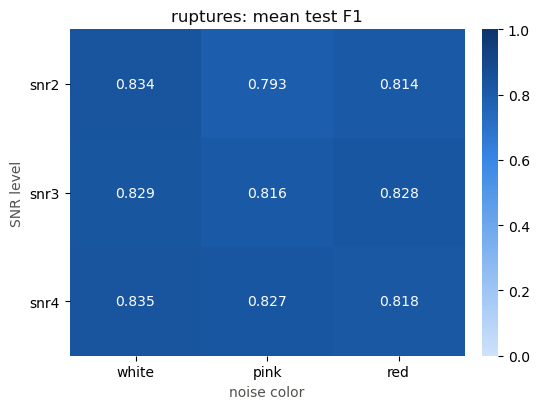

In [7]:
SEQUENTIAL_BLUE = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#1c5cab', '#0d366b']
CMAP = plt.matplotlib.colors.LinearSegmentedColormap.from_list('seq_blue', SEQUENTIAL_BLUE)

methods_present = sorted(df['method'].unique())
fig, axes = plt.subplots(1, len(methods_present), figsize=(5.5 * len(methods_present), 4.2), squeeze=False)
axes = axes[0]

for ax, method in zip(axes, methods_present):
    pivot = (df[df['method'] == method]
             .groupby(['level', 'color'])['test_f1'].mean()
             .unstack('color')
             .reindex(index=EXPECTED_LEVELS, columns=EXPECTED_COLORS))

    im = ax.imshow(pivot.values, cmap=CMAP, vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_title(f'{method}: mean test F1', color='#0b0b0b')
    ax.set_xlabel('noise color', color='#52514e')
    ax.set_ylabel('SNR level', color='#52514e')
    for spine in ax.spines.values():
        spine.set_visible(False)

    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = pivot.values[i, j]
            if np.isnan(val):
                ax.text(j, i, 'n/a', ha='center', va='center', color='#898781', fontsize=9)
            else:
                label_color = '#ffffff' if val > 0.55 else '#0b0b0b'
                ax.text(j, i, f'{val:.3f}', ha='center', va='center', color=label_color, fontsize=10)

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.outline.set_visible(False)

fig.tight_layout()
plt.show()


## F1 vs. SNR level, by noise color

Fixed categorical order (white → slot 1, pink → slot 2, red → slot 3) so
color assignment stays stable across re-runs of this notebook regardless of
which conditions happen to be finished yet. One panel per method; a color
with only one completed level so far is drawn as a lone marker rather than
a misleading single-segment line.

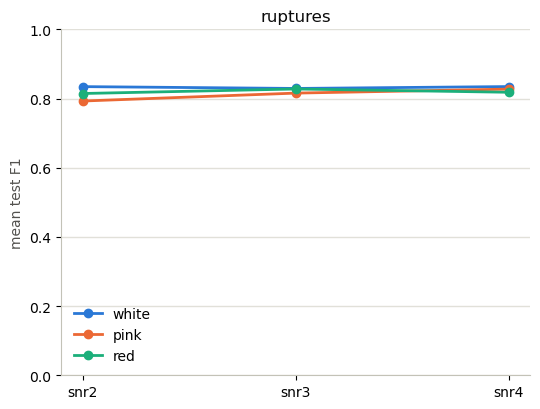

In [8]:
CATEGORICAL = {'white': '#2a78d6', 'pink': '#eb6834', 'red': '#1baf7a'}

fig, axes = plt.subplots(1, len(methods_present), figsize=(5.5 * len(methods_present), 4.2), squeeze=False)
axes = axes[0]

for ax, method in zip(axes, methods_present):
    sub = df[df['method'] == method]
    for color in EXPECTED_COLORS:
        s = (sub[sub['color'] == color]
             .groupby('level')['test_f1'].mean()
             .reindex(EXPECTED_LEVELS))
        present = s.dropna()
        if present.empty:
            continue
        xs = [EXPECTED_LEVELS.index(lv) for lv in present.index]
        if len(present) == 1:
            ax.scatter(xs, present.values, color=CATEGORICAL[color], s=60, zorder=3, label=color)
        else:
            ax.plot(xs, present.values, marker='o', linewidth=2, color=CATEGORICAL[color], label=color)

    ax.set_xticks(range(len(EXPECTED_LEVELS)))
    ax.set_xticklabels(EXPECTED_LEVELS)
    ax.set_ylim(0, 1)
    ax.set_ylabel('mean test F1', color='#52514e')
    ax.set_title(method, color='#0b0b0b')
    ax.grid(axis='y', color='#e1e0d9', linewidth=1, zorder=0)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color('#c3c2b7')
    ax.legend(frameon=False)

fig.tight_layout()
plt.show()


## Which algorithm/parameters won, per condition

Mode of the selected `algo` (or full param set, for methods without one)
across folds in each condition — and how often the winning value sits at
the *edge* of the grid that was actually searched. A parameter that's
consistently pinned to the smallest/largest searched value is a sign the
grid may need widening before trusting the reported optimum, not evidence
that value is truly best.

In [9]:
if 'algo' in df.columns:
    print("Selected algo, by condition (fold counts):")
    print(df.groupby(['level', 'color'])['algo'].value_counts().to_string())


Selected algo, by condition (fold counts):
level  color  algo    
snr2   pink   Pelt        5
       red    BottomUp    5
       white  Pelt        4
              BottomUp    1
snr3   pink   BottomUp    5
       red    BottomUp    5
       white  Pelt        3
              BottomUp    2
snr4   pink   BottomUp    5
       red    BottomUp    3
              Pelt        2
       white  BottomUp    5


In [10]:
def edge_flag(series, grid):
    lo, hi = min(grid), max(grid)
    at_lo = (series == lo).mean()
    at_hi = (series == hi).mean()
    return at_lo, at_hi

if 'pen' in df.columns:
    rup = df[df['method'] == 'ruptures']
    rows = []
    for (level, color), g in rup.groupby(['level', 'color']):
        pen_lo, pen_hi = edge_flag(g['pen'], RUPTURES_PENS)
        ms_lo, ms_hi = edge_flag(g['min_size'], RUPTURES_MIN_SIZES)
        rows.append({
            'level': level, 'color': color, 'n_folds': len(g),
            'pen_at_min_grid_edge': f'{pen_lo:.0%}', 'pen_at_max_grid_edge': f'{pen_hi:.0%}',
            'min_size_at_min_grid_edge': f'{ms_lo:.0%}', 'min_size_at_max_grid_edge': f'{ms_hi:.0%}',
        })
    edge_df = pd.DataFrame(rows)
    print(edge_df.to_string(index=False))
    if ((edge_df['pen_at_min_grid_edge'] != '0%') | (edge_df['min_size_at_min_grid_edge'] != '0%')).any():
        print("\n⚠ One or more conditions are consistently selecting the SMALLEST searched pen/min_size."
              "\n  Consider widening RUPTURES_PENS / RUPTURES_MIN_SIZES downward in cv_noise_sensitivity.py"
              "\n  before treating the reported optimum as final.")


level color  n_folds pen_at_min_grid_edge pen_at_max_grid_edge min_size_at_min_grid_edge min_size_at_max_grid_edge
 snr2  pink        5                 100%                   0%                      100%                        0%
 snr2   red        5                 100%                   0%                      100%                        0%
 snr2 white        5                 100%                   0%                      100%                        0%
 snr3  pink        5                 100%                   0%                      100%                        0%
 snr3   red        5                 100%                   0%                      100%                        0%
 snr3 white        5                 100%                   0%                      100%                        0%
 snr4  pink        5                 100%                   0%                      100%                        0%
 snr4   red        5                 100%                   0%                  

## Runtime diagnostics

Per-fold wall-clock time by condition — useful for spotting which
algo/condition combinations are dominating the walltime budget (per the
script's own notes, Pelt/KernelCPD are expected to be the slow ones).

In [11]:
if 'fold_time_seconds' in df.columns:
    rt = (df.groupby(['level', 'color'])['fold_time_seconds']
            .agg(['mean', 'std', 'min', 'max'])
            .apply(lambda s: s / 3600)
            .round(2)
            .rename(columns=lambda c: f'{c}_hr'))
    print(rt.to_string())


             mean_hr  std_hr  min_hr  max_hr
level color                                 
snr2  pink      2.69    0.04    2.65    2.74
      red       2.35    0.03    2.32    2.38
      white     3.37    0.03    3.34    3.42
snr3  pink      2.87    0.05    2.80    2.94
      red       2.63    0.03    2.61    2.67
      white     3.10    0.04    3.06    3.16
snr4  pink      2.83    0.05    2.77    2.89
      red       2.70    0.04    2.66    2.75
      white     3.04    0.03    3.01    3.09


## Not yet covered by this checkpoint

Flagging explicitly so results here don't get overstated in the abstract:

- **KS-test on the noise grid** — `kstest` is commented out of `METHODS` in
  `cv_noise_sensitivity.py`; nothing in this checkpoint reflects the
  augmented KS-test's noise sensitivity. (`cv_results_KS_test.csv` in the
  project root is a *separate*, single-fixed-trajectory calibration — not
  from this grid — and shouldn't be conflated with it.)
- **LERM** — not implemented in this script at all yet.
- **NGRIP transfer** — applying each condition's optimized parameters to
  the real NGRIP δ¹⁸O record hasn't been run; that's a separate step once
  the synthetic-grid optimization is complete.

Once those exist as their own checkpoint/results files, extend this
notebook with a matching load + summary section rather than treating it as
a one-off — same pattern as `load_checkpoint()` above, generalized to
whichever method name shows up in the `method` column.